# Exploration 1 — Univers, prix et cibles

**But** : comprendre les données de prix avant de définir les cibles des modèles
(horizons, seuils, classes) et la validation.

**Données** (produites par `data_pipeline/`, voir les commits de la PR #2) :
- `sp500_membership.parquet` : périodes d'appartenance au S&P 500 par entreprise (`company_id` = CIK SEC regroupés) ;
- `price_panel.parquet` : une série journalière par entreprise depuis 2010, statut `validated` / `extended`,
  rendement total `ret` (NaN les jours de scission / dividende spécial, `corp_action`) ;
- relevés Vanguard 500 (positions réelles de l'indice) ; SPY comme référence de l'indice.

**Questions**
1. Quelle part de l'indice couvre-t-on, et qui manque ?
2. Ce qui manque biaise-t-il les rendements (biais du survivant) ?
3. À quoi ressemblent les rendements à 1, 5 et 21 jours ?
4. Les labels actuels (vente / neutre / achat à ±1,5 % contre le S&P sur 5 jours) tiennent-ils ?
5. Y a-t-il du signal, et à quel horizon ?
6. Données manquantes et chevauchement des labels : conséquences pour la validation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = (
    Path.cwd().resolve().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd().resolve()
)
PIPE = ROOT / "data_pipeline"
CACHE = PIPE / "cache"
sys.path.insert(0, str(PIPE))
START = pd.Timestamp("2010-01-01")
HORIZONS = (1, 5, 21)

# Chart style: validated reference palette, thin marks, recessive grid.
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"  # categorical slots 1-3
SELL, HOLD, BUY = "#e34948", "#a8a7a1", "#2a78d6"  # diverging poles + neutral
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "text.color": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "legend.frameon": False,
        "figure.dpi": 110,
        "font.size": 10,
    }
)


def pct(x):
    return f"{x:.1%}"

## 0. Chargement

In [2]:
panel = pd.read_parquet(
    CACHE / "price_panel.parquet",
    columns=["date", "company_id", "status", "ret", "corp_action"],
)
spells = pd.read_parquet(CACHE / "sp500_membership.parquet")
calendar = pd.DatetimeIndex(sorted(panel["date"].unique()))

R = panel.pivot(index="date", columns="company_id", values="ret").reindex(
    calendar
)
STATUS = panel.pivot(
    index="date", columns="company_id", values="status"
).reindex(calendar)


def member_days(spells: pd.DataFrame, days: pd.DatetimeIndex) -> pd.DataFrame:
    rows = []
    for s in spells.itertuples():
        end = s.end if pd.notna(s.end) else days.max() + pd.Timedelta(days=1)
        d = days[(days >= s.start) & (days < end)]
        rows.append(pd.DataFrame({"date": d, "company_id": s.company_id}))
    return pd.concat(rows).drop_duplicates()


MD = member_days(spells, calendar[calendar >= START])
# In-index mask aligned with R (companies without any price are
# absent from R).
MI = (
    MD[MD["company_id"].isin(R.columns)]
    .assign(v=True)
    .pivot(index="date", columns="company_id", values="v")
    .reindex(index=calendar, columns=R.columns)
    .fillna(False)
    .astype(bool)
)


def benchmark(symbol: str) -> pd.Series:
    """Daily total return of an ETF (adjusted close), cached.

    SPY = S&P 500, RSP = S&P 500 equal weight.
    """
    path = CACHE / "prices" / "benchmark" / f"{symbol}.parquet"
    if not path.exists():
        import yfinance as yf

        df = yf.Ticker(symbol).history(start="2008-01-01", auto_adjust=False)
        df.index = df.index.tz_localize(None).normalize()
        path.parent.mkdir(parents=True, exist_ok=True)
        df.to_parquet(path)
    return pd.read_parquet(path)["Adj Close"].pct_change().reindex(calendar)


spy_ret, rsp_ret = benchmark("SPY"), benchmark("RSP")
print(
    f"panel: {len(panel):,} rows, {R.shape[1]} companies,"
    f" {calendar.min().date()} -> {calendar.max().date()}"
)
print(
    f"membership: {spells['company_id'].nunique()} companies, member-days"
    f" since 2010: {len(MD):,}"
)

panel: 2,183,413 rows, 700 companies, 2008-11-28 -> 2026-11-19
membership: 976 companies, member-days since 2010: 2,117,103


## 1. Couverture de l'univers

Pour chaque jour où une entreprise est membre de l'indice : a-t-on un prix validé (entre deux relevés
Vanguard concordants), étendu (même série, non vérifiable) ou rien ?

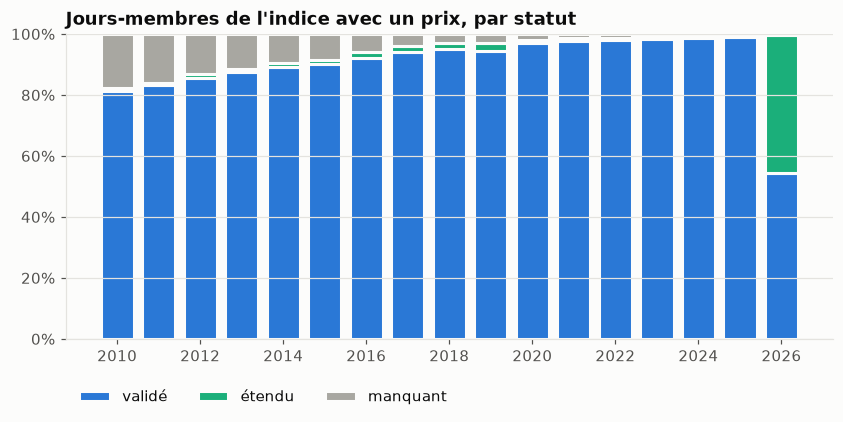

status,validated,extended,missing
date,,,
2010,81.3%,0.9%,17.8%
2011,83.4%,0.6%,16.0%
2012,85.6%,1.3%,13.1%
2013,87.5%,1.0%,11.5%
2014,89.1%,1.5%,9.4%
2015,90.0%,1.5%,8.5%
2016,92.2%,2.0%,5.8%
2017,94.2%,1.9%,3.9%
2018,95.1%,1.8%,3.1%


In [3]:
cov = MD.merge(
    panel[["date", "company_id", "status"]],
    on=["date", "company_id"],
    how="left",
)
cov["status"] = cov["status"].fillna("missing")
by_year = pd.crosstab(cov["date"].dt.year, cov["status"], normalize="index")[
    ["validated", "extended", "missing"]
]

fig, ax = plt.subplots(figsize=(9, 3.6))
bottom = np.zeros(len(by_year))
for col, color, label in [
    ("validated", S1, "validé"),
    ("extended", S3, "étendu"),
    ("missing", HOLD, "manquant"),
]:
    ax.bar(
        by_year.index,
        by_year[col],
        bottom=bottom,
        color=color,
        label=label,
        width=0.8,
        edgecolor=SURFACE,
        linewidth=2,
    )
    bottom += by_year[col].values
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xticks(by_year.index[::2])
ax.set_title("Jours-membres de l'indice avec un prix, par statut")
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, -0.12))
ax.grid(axis="x", visible=False)
plt.show()
by_year.style.format("{:.1%}")

2026 : « étendu » élevé parce que le dernier relevé Vanguard date du 30/06/2026 (rien n'est vérifiable après).

**Qui manque ?** Les jours manquants se concentrent-ils sur des entreprises sorties tôt de l'indice
(rachetées, faillites) ? C'est le cas dangereux : ce sont justement celles dont le parcours finit mal ou de façon atypique.

In [4]:
miss = cov[cov["status"] == "missing"]
last_end = spells.groupby("company_id")["end"].max()
names = spells.groupby("company_id")["name"].last()
by_comp = miss.groupby("company_id").size().rename("missing_days").to_frame()
by_comp["left_index"] = last_end.reindex(by_comp.index)
by_comp["name"] = names.reindex(by_comp.index)
still = by_comp["left_index"].isna()
print(f"entreprises avec des jours manquants : {len(by_comp)}")
print(
    f"  dont encore dans l'indice aujourd'hui : {still.sum()}"
    f" ({by_comp.loc[still, 'missing_days'].sum() / len(miss):.1%} des jours"
    " manquants)"
)
gone = by_comp[~still]
for y in (2012, 2015, 2018):
    share = gone.loc[
        gone["left_index"].dt.year <= y, "missing_days"
    ].sum() / len(miss)
    print(
        f"  sorties de l'indice avant fin {y} : {share:.1%} des jours"
        " manquants"
    )
by_comp.sort_values("missing_days", ascending=False).head(15)

entreprises avec des jours manquants : 141
  dont encore dans l'indice aujourd'hui : 9 (2.6% des jours manquants)
  sorties de l'indice avant fin 2012 : 11.9% des jours manquants
  sorties de l'indice avant fin 2015 : 36.6% des jours manquants
  sorties de l'indice avant fin 2018 : 70.5% des jours manquants


,missing_days,left_index,name
company_id,,,
cik:51644,4023,2025-12-31,Interpublic Group of Cos Inc/The
cik:1393612,3895,2025-06-30,Discover Financial Services
cik:1015780,2768,2020-12-31,E*TRADE Financial Corp
cik:1578845,2640,2020-06-30,Allergan PLC
cik:750556,2500,2019-12-09,SunTrust Banks Inc.
cik:356028,2451,2019-09-30,CA Inc.
cik:773910,2416,2019-08-09,Anadarko Petroleum Corp.
cik:1732845,2264,2024-09-30,Westrock Co
cik:1110783,2121,2018-06-07,Monsanto Co.


## 2. Biais de couverture : notre univers contre l'indice réel

On reconstruit un indice pondéré par capitalisation **avec uniquement les entreprises dont on a les prix** :
poids réels de Vanguard à chaque relevé, qui dérivent avec les rendements jusqu'au relevé suivant.
Si ce qui manque était neutre, cet indice suivrait le SPY (à ses frais de 0,09 %/an près).
Un écart positif = on surestime les rendements (on a surtout gardé les gagnants).

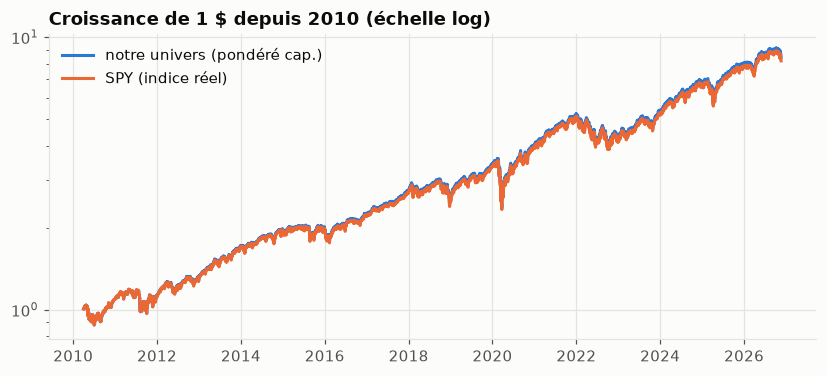

annualisé : univers 13.71%, SPY 13.49%, écart +0.22%/an
tracking error annualisée : 0.97%


,univers,SPY,écart,poids couvert
2010,+9.01%,+9.14%,-0.13%,92.0%
2011,+2.62%,+1.89%,+0.73%,92.3%
2012,+16.17%,+15.99%,+0.18%,93.3%
2013,+32.52%,+32.31%,+0.21%,93.8%
2014,+13.39%,+13.46%,-0.07%,94.5%
2015,+1.57%,+1.23%,+0.34%,95.3%
2016,+12.26%,+12.00%,+0.26%,96.7%
2017,+22.13%,+21.71%,+0.43%,97.7%
2018,-4.44%,-4.57%,+0.13%,97.8%
2019,+31.42%,+31.22%,+0.20%,99.0%


In [5]:
from membership.build_membership import assign_company_ids, load_holdings

h = load_holdings()
h["company_id"] = h["entity"].map(assign_company_ids(h))
W = h.groupby(["date", "company_id"])["weight"].sum().unstack()
snaps = W.index[(W.index >= pd.Timestamp("2009-12-31"))]


def covered_index(
    R: pd.DataFrame, W: pd.DataFrame, snaps
) -> tuple[pd.Series, pd.Series]:
    """Cap-weighted index return over companies with prices.

    Also returns the weight covered by those companies.
    """
    rets, covered = pd.Series(np.nan, index=R.index), {}
    for k, s in enumerate(snaps):
        end = snaps[k + 1] if k + 1 < len(snaps) else R.index.max()
        days = R.index[(R.index > s) & (R.index <= end)]
        w = W.loc[s].dropna()
        cols = [
            c
            for c in w.index
            if c in R.columns and R.loc[days, c].notna().mean() >= 0.9
        ]
        covered[s] = w[cols].sum()
        r = R.loc[days, cols].fillna(0.0).values
        w0 = (w[cols] / w[cols].sum()).values
        value = w0 * np.cumprod(1 + r, axis=0)
        prev = np.vstack([w0, value[:-1]])
        rets[days] = (prev * r).sum(axis=1) / prev.sum(axis=1)
    return rets, pd.Series(covered)


idx_ret, covered_w = covered_index(R, W, snaps)
both = pd.DataFrame({"univers": idx_ret, "SPY": spy_ret}).dropna()
yearly = both.groupby(both.index.year).apply(lambda g: (1 + g).prod() - 1)
yearly["écart"] = yearly["univers"] - yearly["SPY"]
yearly["poids couvert"] = covered_w.groupby(covered_w.index.year).mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
cum = (1 + both).cumprod()
ax.plot(
    cum.index, cum["univers"], color=S1, label="notre univers (pondéré cap.)"
)
ax.plot(cum.index, cum["SPY"], color=S2, label="SPY (indice réel)")
ax.set_yscale("log")
ax.set_title("Croissance de 1 $ depuis 2010 (échelle log)")
ax.legend(loc="upper left")
plt.show()
total = (1 + both).prod() - 1
ann = (1 + both).prod() ** (252 / len(both)) - 1
print(
    f"annualisé : univers {ann['univers']:.2%}, SPY {ann['SPY']:.2%}, écart"
    f" {ann['univers'] - ann['SPY']:+.2%}/an"
)
print(
    "tracking error annualisée :"
    f" {(both['univers'] - both['SPY']).std() * np.sqrt(252):.2%}"
)
yearly.style.format("{:+.2%}", subset=["univers", "SPY", "écart"]).format(
    "{:.1%}", subset=["poids couvert"]
)

**À poids égal.** Le modèle traite chaque action de la même façon, et les entreprises manquantes sont plutôt
petites : le biais peut être plus fort à poids égal. Référence : RSP (S&P 500 équipondéré, rééquilibré chaque
trimestre). On reproduit la même règle avec nos actions : poids égaux à chaque fin de trimestre, puis dérive.

In [6]:
quarter_ends = pd.DatetimeIndex(
    [
        calendar[calendar <= q].max()
        for q in pd.date_range(START, calendar.max(), freq="QE")
    ]
).unique()
EQ = MI.loc[quarter_ends].astype(
    float
)  # equal weight on every member with a price history
EQ = EQ.where(EQ > 0)
eq_ret, eq_cov = covered_index(R, EQ, quarter_ends)
members_q = MD.groupby("date").size().reindex(quarter_ends)
both_eq = pd.DataFrame(
    {"univers (poids égal)": eq_ret, "RSP": rsp_ret}
).dropna()
yearly_eq = both_eq.groupby(both_eq.index.year).apply(
    lambda g: (1 + g).prod() - 1
)
yearly_eq["écart"] = yearly_eq.iloc[:, 0] - yearly_eq["RSP"]
yearly_eq["membres couverts"] = (
    (eq_cov / members_q).groupby(quarter_ends.year).mean()
)
ann_eq = (1 + both_eq).prod() ** (252 / len(both_eq)) - 1
print(
    f"annualisé : univers {ann_eq.iloc[0]:.2%}, RSP {ann_eq['RSP']:.2%} (frais"
    f" 0,20 %/an), écart {ann_eq.iloc[0] - ann_eq['RSP']:+.2%}/an"
)
print(
    "tracking error annualisée :"
    f" {(both_eq.iloc[:, 0] - both_eq['RSP']).std() * np.sqrt(252):.2%}"
)
yearly_eq.style.format("{:+.2%}", subset=list(yearly_eq.columns[:3])).format(
    "{:.1%}", subset=["membres couverts"]
)

annualisé : univers 12.65%, RSP 11.95% (frais 0,20 %/an), écart +0.70%/an
tracking error annualisée : 1.04%


,univers (poids égal),RSP,écart,membres couverts
2010,+12.91%,+12.37%,+0.54%,82.4%
2011,+0.88%,-0.66%,+1.54%,84.3%
2012,+18.34%,+17.16%,+1.17%,86.7%
2013,+37.10%,+35.54%,+1.56%,88.8%
2014,+14.58%,+14.06%,+0.51%,90.4%
2015,-2.40%,-2.67%,+0.26%,91.3%
2016,+15.67%,+14.50%,+1.17%,94.2%
2017,+19.17%,+18.52%,+0.65%,95.9%
2018,-7.78%,-7.84%,+0.06%,96.4%
2019,+29.36%,+28.91%,+0.45%,97.0%


## 3. Rendements à 1, 5 et 21 jours

Rendements futurs calculés à partir de `ret` (rendement total, dividendes inclus), pour chaque jour où l'action
est dans l'indice. Une fenêtre qui contient un jour inconnu (trou, scission) donne un rendement inconnu.

In [7]:
L = np.log1p(R)
spy_L = np.log1p(spy_ret)


def forward(logret, h):
    """Simple return over the next h trading days.

    NaN if any day is unknown.
    """
    return np.expm1(logret.rolling(h, min_periods=h).sum().shift(-h))


FWD = {h: forward(L, h).where(MI) for h in HORIZONS}
SPY_FWD = {h: forward(spy_L, h) for h in HORIZONS}
EXC = {
    h: FWD[h].sub(SPY_FWD[h], axis=0) for h in HORIZONS
}  # excess return over the index

rows = []
for h in HORIZONS:
    for kind, M in (("action", FWD[h]), ("excès vs SPY", EXC[h])):
        v = M.stack().dropna().values
        q = np.quantile(v, [0.01, 0.05, 0.5, 0.95, 0.99])
        rows.append(
            {
                "horizon": f"{h} j",
                "rendement": kind,
                "n": len(v),
                "moyenne": v.mean(),
                "écart-type": v.std(),
                "asymétrie": stats.skew(v),
                "kurtosis (excès)": stats.kurtosis(v),
                "q1%": q[0],
                "q5%": q[1],
                "médiane": q[2],
                "q95%": q[3],
                "q99%": q[4],
            }
        )
dist = pd.DataFrame(rows).set_index(["horizon", "rendement"])
dist.style.format(
    {"n": "{:,.0f}", "asymétrie": "{:.2f}", "kurtosis (excès)": "{:.1f}"}
    | {
        c: "{:.2%}"
        for c in [
            "moyenne",
            "écart-type",
            "q1%",
            "q5%",
            "médiane",
            "q95%",
            "q99%",
        ]
    }
)

**Queues épaisses** : rendements en excès standardisés comparés à une loi normale (échelle log).
Une kurtosis élevée veut dire que les mouvements extrêmes sont bien plus fréquents que ne le prévoit une normale,
ce qui pèse sur les pertes de type MSE et sur des seuils fixes.

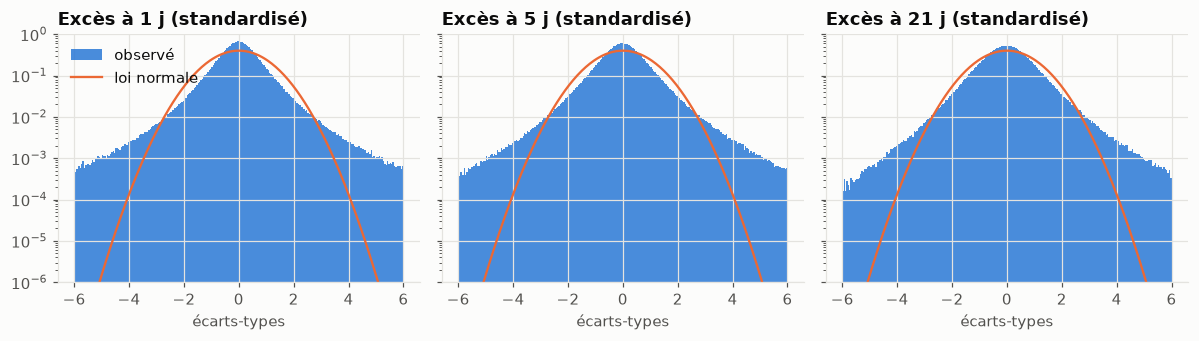

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
grid = np.linspace(-6, 6, 241)
for ax, h in zip(axes, HORIZONS):
    v = EXC[h].stack().dropna().values
    z = (v - v.mean()) / v.std()
    ax.hist(z, bins=grid, density=True, color=S1, alpha=0.85, label="observé")
    ax.plot(
        grid,
        stats.norm.pdf(grid),
        color=S2,
        linewidth=1.5,
        label="loi normale",
    )
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1)
    ax.set_title(f"Excès à {h} j (standardisé)")
    ax.set_xlabel("écarts-types")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Régimes** : la dispersion entre actions (écart-type en coupe des rendements à 21 jours) et la volatilité du marché
changent fortement dans le temps. Un seuil fixe en % ne veut donc pas dire la même chose en 2017 et en 2020.

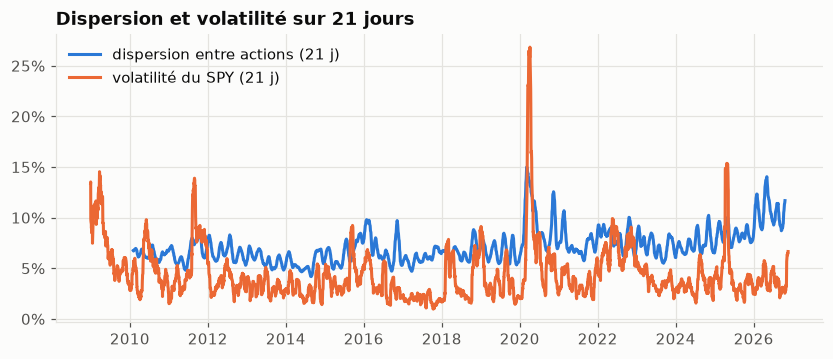

In [9]:
disp = FWD[21].std(axis=1).rolling(21).mean()
mkt_vol = spy_ret.rolling(21).std() * np.sqrt(21)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(disp.index, disp, color=S1, label="dispersion entre actions (21 j)")
ax.plot(mkt_vol.index, mkt_vol, color=S2, label="volatilité du SPY (21 j)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Dispersion et volatilité sur 21 jours")
ax.legend(loc="upper left")
plt.show()

**Excès médian par année.** L'indice pondéré par capitalisation est tiré par les plus grosses entreprises :
l'action « typique » fait moins bien que lui quand quelques géants dominent (2023-2024).

In [10]:
med = pd.DataFrame(
    {
        f"{h} j": (
            EXC[h]
            .loc[START:]
            .stack()
            .groupby(level=0)
            .median()
            .groupby(lambda d: d.year)
            .mean()
        )
        for h in (5, 21)
    }
)
med.T.style.format("{:+.2%}")

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
5 j,+0.03%,-0.01%,+0.03%,+0.03%,-0.01%,-0.07%,+0.03%,+0.01%,-0.01%,+0.02%,-0.11%,-0.04%,+0.25%,-0.22%,-0.27%,-0.12%,+0.07%
21 j,+0.24%,+0.02%,+0.13%,+0.22%,+0.07%,-0.19%,+0.12%,-0.01%,-0.04%,-0.16%,-0.55%,-0.19%,+0.73%,-1.05%,-0.83%,-0.66%,-0.16%


## 4. Les labels actuels : ±1,5 % d'excès sur 5 jours

Règle de l'ancien projet : `VENTE` si excès < −1,5 %, `ACHAT` si > +1,5 %, `NEUTRE` sinon.
On regarde l'équilibre des classes à 5 et 21 jours, puis sa stabilité dans le temps.

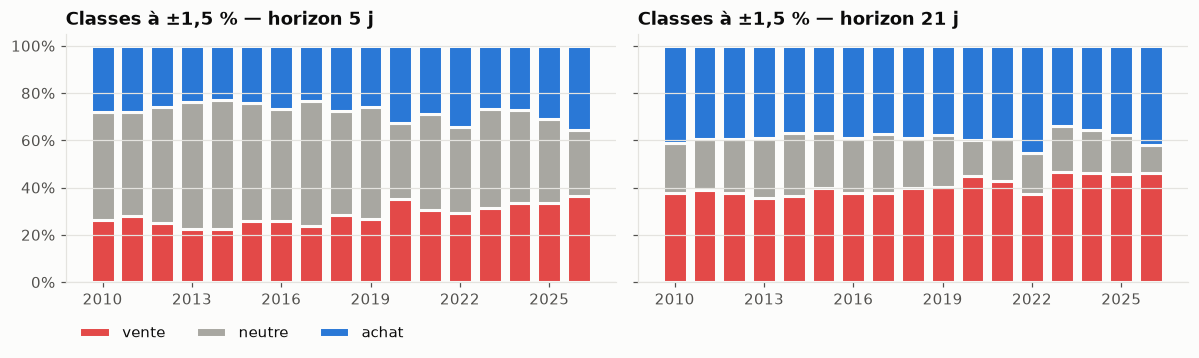

,5 j,21 j
achat,27.8%,38.7%
neutre,43.6%,20.5%
vente,28.6%,40.8%


In [11]:
def classes(ex, thr):
    return ex.where(ex.isna(), np.select([ex < -thr, ex > thr], [-1, 1], 0))


def shares_by(lbl, freq):
    s = lbl.stack().dropna()
    grp = (
        s.index.get_level_values(0).year
        if freq == "Y"
        else s.index.get_level_values(0).to_period("M")
    )
    return pd.crosstab(grp, s, normalize="index").rename(
        columns={-1: "vente", 0: "neutre", 1: "achat"}
    )


LBL = {h: classes(EXC[h], 0.015) for h in (5, 21)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, h in zip(axes, (5, 21)):
    sh = shares_by(LBL[h], "Y")
    bottom = np.zeros(len(sh))
    for col, color in (("vente", SELL), ("neutre", HOLD), ("achat", BUY)):
        ax.bar(
            sh.index,
            sh[col],
            bottom=bottom,
            color=color,
            label=col,
            width=0.8,
            edgecolor=SURFACE,
            linewidth=2,
        )
        bottom += sh[col].values
    ax.set_title(f"Classes à ±1,5 % — horizon {h} j")
    ax.grid(axis="x", visible=False)
    ax.set_xticks(sh.index[::3])
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].legend(ncols=3, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        f"{h} j": (
            LBL[h]
            .stack()
            .dropna()
            .value_counts(normalize=True)
            .rename({-1: "vente", 0: "neutre", 1: "achat"})
        )
        for h in (5, 21)
    }
).style.format("{:.1%}")

**Alternative 1 — seuil ajusté à la volatilité de l'action** : on divise l'excès par la volatilité récente de
l'action (écart-type des 60 derniers jours d'excès quotidien, connu en *t*) × √h, puis seuil ±0,43
(≈ un tiers par classe si c'était normal).

**Alternative 2 — terciles en coupe** : chaque jour, le tiers des actions le plus faible = vente, le plus fort = achat.
Un tiers par classe par construction, indépendant du régime de marché, et c'est exactement le problème
d'un sélectionneur d'actions (classer les actions entre elles).

On compare la part de `neutre` mois par mois.

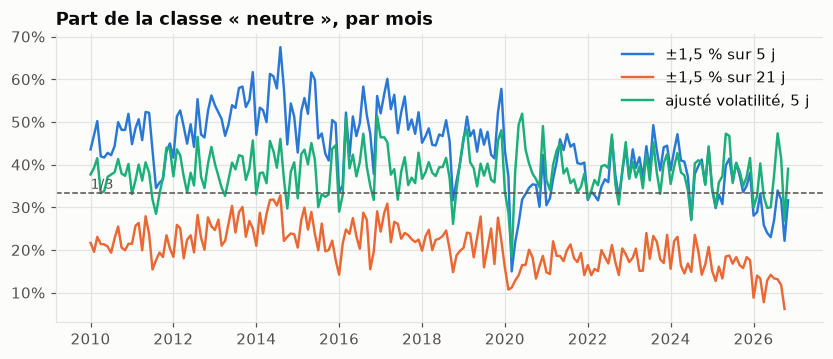

,"±1,5 % sur 5 j","±1,5 % sur 21 j","ajusté volatilité, 5 j"
mean,43.8%,20.6%,38.4%
std,9.0%,5.0%,5.1%
min,15.0%,6.2%,18.5%
max,67.5%,32.8%,51.9%


In [12]:
daily_exc = R.sub(spy_ret, axis=0)
vol60 = daily_exc.rolling(60, min_periods=40).std()
Z5 = EXC[5] / (vol60 * np.sqrt(5))
LBL_VOL5 = classes(Z5, 0.43)
neutral = pd.DataFrame(
    {
        "±1,5 % sur 5 j": shares_by(LBL[5], "M")["neutre"],
        "±1,5 % sur 21 j": shares_by(LBL[21], "M")["neutre"],
        "ajusté volatilité, 5 j": shares_by(LBL_VOL5, "M")["neutre"],
    }
)
neutral.index = neutral.index.to_timestamp()
fig, ax = plt.subplots(figsize=(9, 3.4))
for col, color in zip(neutral.columns, (S1, S2, S3)):
    ax.plot(neutral.index, neutral[col], color=color, label=col, linewidth=1.6)
ax.axhline(1 / 3, color=INK2, linewidth=1, linestyle="--")
ax.text(neutral.index[0], 1 / 3 + 0.01, "1/3", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Part de la classe « neutre », par mois")
ax.legend(loc="upper right")
plt.show()
neutral.describe().loc[["mean", "std", "min", "max"]].style.format("{:.1%}")

## 5. Y a-t-il du signal, et à quel horizon ?

Test rapide avec trois signaux connus de la littérature, calculés uniquement avec le passé :
- **momentum 12-1** : rendement de *t*−252 à *t*−21 ;
- **retournement court terme** : rendement des 5 derniers jours ;
- **volatilité 60 j**.

Mesure : **IC de rang** = corrélation de Spearman, chaque jour, entre le signal et l'excès futur, sur toutes les
actions de l'indice. Un IC moyen de 0,02–0,05 est typique d'un signal utile. Le t-stat est calculé sur des dates
espacées d'au moins h jours (pas de chevauchement).

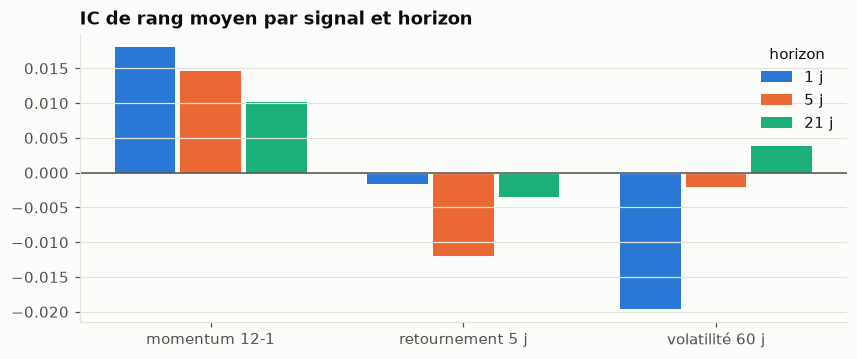

In [13]:
SIG = {
    "momentum 12-1": L.rolling(231, min_periods=231).sum().shift(21),
    "retournement 5 j": L.rolling(5, min_periods=5).sum(),
    "volatilité 60 j": R.rolling(60, min_periods=40).std(),
}


def rank_ic(S, Y, dates):
    out = {}
    for d in dates:
        s, y = S.loc[d], Y.loc[d]
        ok = s.notna() & y.notna()
        if ok.sum() >= 100:
            out[d] = s[ok].rank().corr(y[ok].rank())
    return pd.Series(out)


base = calendar[(calendar >= START) & (calendar <= calendar[-22])]
ic_rows = []
for name, S in SIG.items():
    for h in HORIZONS:
        ic = rank_ic(S, EXC[h], base[:: max(5, h)])
        ic_rows.append(
            {
                "signal": name,
                "horizon": f"{h} j",
                "IC moyen": ic.mean(),
                "t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
                "% dates IC>0": (ic > 0).mean(),
                "n dates": len(ic),
            }
        )
ic_tab = pd.DataFrame(ic_rows)

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(SIG))
width = 0.26
for i, (h, color) in enumerate(zip(HORIZONS, (S1, S2, S3))):
    vals = ic_tab[ic_tab["horizon"] == f"{h} j"]["IC moyen"].values
    ax.bar(
        x + (i - 1) * width,
        vals,
        width=width - 0.02,
        color=color,
        label=f"{h} j",
    )
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xticks(x, list(SIG))
ax.grid(axis="x", visible=False)
ax.set_title("IC de rang moyen par signal et horizon")
ax.legend(title="horizon", loc="upper right")
plt.show()
ic_tab.set_index(["signal", "horizon"]).style.format(
    {"IC moyen": "{:+.3f}", "t-stat": "{:+.1f}", "% dates IC>0": "{:.0%}"}
)

## 6. Données manquantes et chevauchement des labels

**Labels inconnus** : jours où l'action est dans l'indice mais où le rendement futur est inconnu
(pas de prix, scission dans la fenêtre, ou cotation qui s'arrête — typiquement un rachat).

In [14]:
has_px = R.notna() & MI
rows = []
for h in HORIZONS:
    in_idx = MI.values.sum()
    lab = FWD[h].notna().values.sum()
    no_px = (MI & R.isna()).values.sum()
    rows.append(
        {
            "horizon": f"{h} j",
            "jours-membres (avec prix)": has_px.values.sum(),
            "label connu": lab / has_px.values.sum(),
            "inconnu malgré un prix en t": 1 - lab / has_px.values.sum(),
        }
    )
pd.DataFrame(rows).set_index("horizon").style.format(
    {
        "jours-membres (avec prix)": "{:,.0f}",
        "label connu": "{:.2%}",
        "inconnu malgré un prix en t": "{:.2%}",
    }
)

,jours-membres (avec prix),label connu,inconnu malgré un prix en t
horizon,,,
1 j,"1,992,803",99.97%,0.03%
5 j,"1,992,803",99.84%,0.16%
21 j,"1,992,803",99.31%,0.69%


**Chevauchement** : avec un label à 21 jours calculé chaque jour, deux jours consécutifs partagent 20 jours sur 21.
L'autocorrélation du label montre combien d'observations sont réellement indépendantes,
et quel écart (*embargo*) laisser entre entraînement et validation pour éviter les fuites.

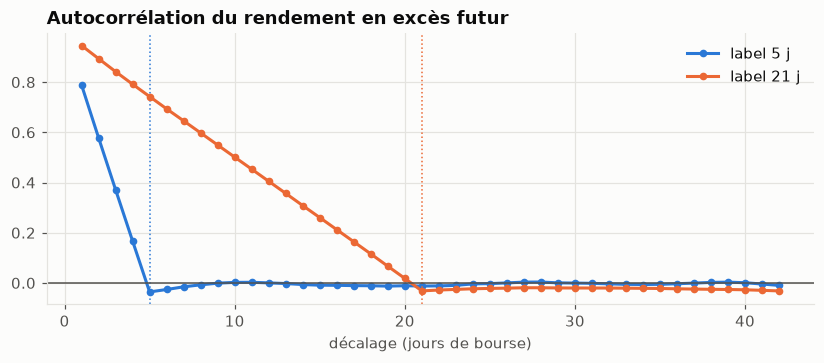

5 j : ~411,198 observations indépendantes équivalentes sur 1,992,803 lignes
21 j : ~99,026 observations indépendantes équivalentes sur 1,992,803 lignes


In [15]:
rng = np.random.default_rng(0)
sample = rng.choice(
    [c for c in R.columns if MI[c].sum() > 1000], size=150, replace=False
)
lags = np.arange(1, 43)
acf = {}
for h, color in zip((5, 21), (S1, S2)):
    acf[h] = [
        np.nanmean([EXC[h][c].autocorr(lag) for c in sample]) for lag in lags
    ]
fig, ax = plt.subplots(figsize=(9, 3.2))
for h, color in zip((5, 21), (S1, S2)):
    ax.plot(
        lags,
        acf[h],
        color=color,
        label=f"label {h} j",
        marker="o",
        markersize=4,
    )
    ax.axvline(h, color=color, linewidth=1, linestyle=":")
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xlabel("décalage (jours de bourse)")
ax.set_title("Autocorrélation du rendement en excès futur")
ax.legend(loc="upper right")
plt.show()
for h in (5, 21):
    n_eff = has_px.values.sum() / (1 + 2 * sum(a for a in acf[h] if a > 0))
    print(
        f"{h} j : ~{n_eff:,.0f} observations indépendantes équivalentes sur"
        f" {has_px.values.sum():,} lignes"
    )

## 7. Synthèse

### Données
1. **Couverture** : 82 % des membres de l'indice ont un prix en 2010, 94 % en 2016, 98-99 % depuis 2020.
   97 % des jours manquants concernent des entreprises **sorties de l'indice depuis**.
   Une partie est récupérable : des sociétés rachetées récemment (Interpublic 2025, Discover 2025, E*TRADE 2020,
   SunTrust, CA, Anadarko…) n'ont pas de ticker candidat, alors que Tiingo a probablement leurs prix.
2. **Biais du survivant mesuré** :
   - pondéré par capitalisation : +0,2 %/an contre le SPY, soit à peu près ses frais → négligeable ;
   - **à poids égal** (le point de vue du modèle) : +0,7 %/an contre RSP, dont ~0,2 % de frais → **~0,5 %/an**,
     et **1,2 à 1,6 %/an en 2011-2013** quand 12 à 16 % des membres manquent. Les entreprises manquantes ont fait
     moins bien que la moyenne. Un backtest sur 2010-2015 serait donc un peu optimiste.
3. **Labels inconnus** : < 0,7 % même à 21 jours → négligeable.

### Rendements
4. **Queues très épaisses** : kurtosis 87 à 1 jour, 20 à 5 jours, 9 à 21 jours (0 pour une loi normale).
   Écart-type de l'excès : 1,7 % / 3,8 % / 7,6 %. → Pas de régression MSE sur des rendements bruts ;
   préférer classification ou rangs, et des features robustes (rangs, winsorisation).
5. **Régimes** : dispersion et volatilité varient d'un facteur 3 (2017 calme, 2020 extrême).

### Labels actuels (±1,5 % contre le SPY)
6. À 5 jours, la part de « neutre » vaut 44 % en moyenne mais **de 15 % à 68 % selon le mois** : le modèle
   apprendrait surtout le régime de volatilité du marché, pas à choisir des actions.
7. À 21 jours, « neutre » ne fait que 20 % : le seuil n'a pas de sens à cet horizon.
8. **Dérive vers « vente »** (46 % à 21 jours en 2023-2025) : l'excès médian contre le SPY est négatif
   (−1 % en 2023) parce que quelques géants tirent l'indice pondéré. Comparer à la capitalisation mélange
   sélection d'actions et effet « méga-caps ».
9. Le seuil ajusté à la volatilité stabilise les classes (38 % ± 5 % de neutre). Des **terciles en coupe**
   (chaque jour : tiers inférieur / médian / supérieur de l'excès) donnent un tiers par classe par construction.

### Signal
10. Les signaux classiques sont **faibles mais présents** : momentum 12-1 IC +0,018 (1 j) / +0,015 (5 j),
    retournement 5 j IC −0,012 à 5 j, faible volatilité IC −0,020 à 1 j ; t-stats autour de 2.
    C'est l'ordre de grandeur normal : l'objectif réaliste est un IC de 0,02-0,05, pas 55 % de précision
    « facile ». À 21 jours, trop peu de périodes indépendantes (≈ 200) pour conclure.

### Validation
11. **Chevauchement** : le label à 21 jours reste corrélé jusqu'à 21 jours de décalage → ~99 000 observations
    indépendantes sur 2 millions de lignes (~411 000 à 5 jours). → Validation walk-forward **avec purge et
    embargo ≥ horizon** ; ne pas se fier au nombre de lignes pour juger du surapprentissage.

### Décisions à prendre
- **Définition des labels** : (a) garder ±1,5 % contre le SPY, (b) terciles en coupe de l'excès,
  (c) seuil ajusté à la volatilité. Recommandation : **(b)**, éventuellement contre la moyenne équipondérée de l'univers.
- **Horizons** : garder 5 j (principal) et 21 j ; un horizon journalier n'apporte pas plus de signal mesurable
  ici et multiplie les transactions → à reconsidérer avec un modèle de coûts.
- **Données** : récupérer les sociétés rachetées récemment sans ticker (réduit le biais 2010-2015) avant
  le feature engineering.